# Linear Regression for Insurance Price Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.set_printoptions(suppress=True)
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("insurance.csv")
print(df.columns)

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')


In [3]:
# Convert numeric columns into float
num_col = ["age", "bmi", "children"]
df[num_col] = df[num_col].astype(float)

# Encode the categorical variables
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Feature Engineering
# As you age and have a higher bmi, you seem to pay more
# If you're a smoker with a higher bmi, you also pay more
df['age_bmi'] = df['age'] * df['bmi']
if 'smoker_yes' in df.columns:
    df['bmi_smoker'] = df['bmi'] * df['smoker_yes']
bool_cols = ['sex_male','smoker_yes','region_northwest','region_southeast','region_southwest']
df[bool_cols] = df[bool_cols].astype(int)
Y = df['charges'].values
X = df.drop('charges', axis=1)
df = pd.concat([X, pd.Series(Y, name='charges')], axis=1)

In [4]:
D_total = df.to_numpy()

In [5]:
X_total = D_total[:, :-1]
Y_total = D_total[:, -1]
# I will partion the total for training and test set manually, we can easily do this using sckitlearn but for this time, I'm doing it manually.
# I will take 70% of the total for training and the remaining for test set

In [6]:
# Normalising some features to help GD
cols_normalise = [0, 1, 8] # columns tobe normalised
scaler = StandardScaler()
X_total[:, cols_normalise] = scaler.fit_transform(X_total[:, cols_normalise])
X_train = X_total[:950, :]
Y_train = Y_total[:950]
X_test = X_total[950:, :]
Y_test = Y_total[950:]
m, n = X_train.shape

In [7]:
# Data Preprocessing is done, continue to Regression from here
W = np.random.rand(n)
b = np.zeros(1)

In [8]:
# Lets compute cost
def compute_cost(W, b):
    y_p = X_train @ W + b
    cost = (y_p - Y_train) ** 2
    cost = 1 / (2 * m) * np.sum(cost)
    return cost
compute_cost(W, b)

157735246.76100045

In [9]:
# Now we have to implement gradient function, you can do this with sckitlearn but I like this one
def gradient(W, b):
    dj_dw = np.zeros(n)  # Partial derivative of cost wrt to the weight parameter
    dj_db = 0            # Partial derivative of cost wrt to the bias parameter
    for i in range(m):
        yp = np.dot(W, X_train[i, :]) + b
        loss = yp - Y_train[i]
        for j in range(n):
            dj_dw[j] += loss * X_train[i, j]
        dj_db += loss
    dj_dw *= (1 / m)
    dj_db *= (1 / m)
    return dj_dw, dj_db
        

In [10]:
# Now we have to implement the gradient descent funciton
def gradient_descent(W, b, lr=0.01, epochs=1001):
    cost_for_plot = []    # plotting the cost curve to see how it is doing
    for epoch in range(epochs):
        cost = compute_cost(W, b)
        cost_for_plot.append(cost)
        dj_dw, dj_db = gradient(W, b)
        W -= lr * dj_dw
        b -= lr * dj_db
        if epoch % 200 == 0:
            print(f"The cost at iter {epoch} = {cost_for_plot[epoch]}")

    return W, b, cost_for_plot
        

In [11]:
out = gradient_descent(W, b)

The cost at iter 0 = 157735246.76100045
The cost at iter 200 = 13914006.609496573
The cost at iter 400 = 12900667.973392833
The cost at iter 600 = 12559558.62339226
The cost at iter 800 = 12366247.995005429
The cost at iter 1000 = 12232731.803620733


As you can see the cost is converging after few iterations (epochs), so we can take these posterior parameters the model predicted
after seeing the data

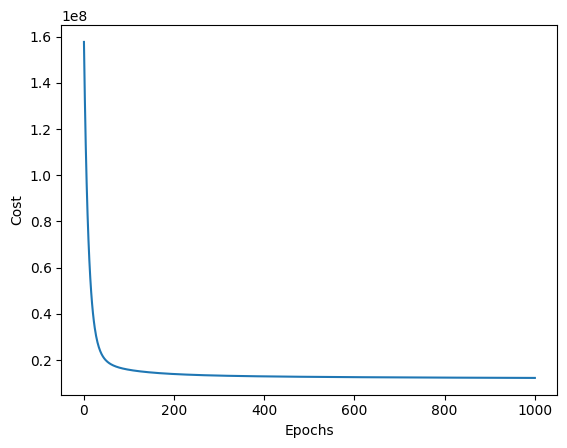

In [12]:
# Let's visualise the cost function, how it is doing after some operations
fig, ax = plt.subplots()
ax.plot(np.arange(1001), out[-1])
ax.set_xlabel("Epochs")
ax.set_ylabel("Cost")

fig.show()

As you can see from the plot, it converged after few iterations (almost 50 iterations), this shows the training is good. we can take these parameters to predict the price of unseen data.

In [13]:
Y_test.shape

(388,)

In [14]:
# Now let's predict the price for the test set, I will return the columns that were normalised to their original status
def predict(W, b):
    cols_to_invert = [0, 1, 8]
    mean = np.mean(X_total[:, cols_to_invert], axis=0)
    std = np.std(X_total[:, cols_to_invert], axis=0)
    X_test[:, cols_to_invert] = X_test[:, cols_to_invert] * std + mean
    yp_test = X_test @ W + b
    return yp_test

In [15]:
# lets compare the prediction price and the actual price, I will invert the normalization because the output won't be the same for both.
prediction_price = predict(out[0], out[1])

In [16]:
prediction_price[:6]

array([ 9242.69565537, 48900.84797133,  5637.45225846, 33978.63606936,
       29090.96484145,  6689.36825383])

In [17]:
Y_test[:6]

array([11534.87265, 47462.894  ,  4527.18295, 38998.546  , 20009.63365,
        3875.7341 ])

In [ ]:
# The model predicts amazingly